In [ ]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

def mechanism_summary_from_runs(runs_path):
    runs = pd.read_csv(runs_path)
    if 'status' in runs.columns:
        runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
    metrics = [
        'created', 'delivered', 'expired', 'pending', 'failed', 'recovered',
        'success_rate', 'completion_rate', 'throughput_per_hour',
        'avg_latency_s', 'median_latency_s', 'p95_latency_s', 'max_latency_s',
        'switch_count', 'fd_switch_count', 'sd_switch_count', 'ce_switch_count',
        'adapt_checks', 'adapt_overhead_ms_mean', 'rtlola_query_ms_mean',
        'scoring_ms_mean', 'wall_time_s', 'event_count',
    ]
    metrics = [metric for metric in metrics if metric in runs.columns]
    for metric in metrics:
        runs[metric] = pd.to_numeric(runs[metric], errors='coerce')
    summary = runs.groupby('coord_label', dropna=False)[metrics].agg(['mean', 'std', 'min', 'max', 'count'])
    summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
    return summary.reset_index()


def first_present(frame, candidates):
    return next((col for col in candidates if col in frame.columns), None)

ROOT = find_results_root(required_any=[Path('RQ1/summary_by_mechanism.csv'), Path('RQ1/runs.csv')])
rq1_dir = ROOT / 'RQ1'
summary_path = rq1_dir / 'summary_by_mechanism.csv'
runs_path = rq1_dir / 'runs.csv'

if summary_path.exists():
    df = pd.read_csv(summary_path)
elif runs_path.exists():
    df = mechanism_summary_from_runs(runs_path)
else:
    raise FileNotFoundError(f'Neither {summary_path} nor {runs_path} exists')

order = [label for label in COORD_ORDER if label in set(df['coord_label'].astype(str))]
df['coord_label'] = pd.Categorical(df['coord_label'], categories=order, ordered=True)
df = df.sort_values('coord_label')
labels = df['coord_label'].astype(str).tolist()

runs_col = first_present(df, ['created_count', 'delivered_count', 'wall_time_s_count', 'event_count_count', 'runs'])
table = pd.DataFrame({'coord_label': labels})
if runs_col:
    table['runs'] = pd.to_numeric(df[runs_col], errors='coerce').astype('Int64')
for source, target in [
    ('delivered_mean', 'delivered_tasks'),
    ('success_rate_mean', 'success_rate'),
    ('throughput_per_hour_mean', 'throughput_per_hour'),
    ('avg_latency_s_mean', 'avg_latency_s'),
    ('p95_latency_s_mean', 'p95_latency_s'),
    ('switch_count_mean', 'coordination_switches'),
]:
    if source in df.columns:
        table[target] = pd.to_numeric(df[source], errors='coerce')
round_cols = [col for col in table.columns if col not in {'coord_label', 'runs'}]
table[round_cols] = table[round_cols].round(3)

plots = [
    ('success_rate_mean', 'Success rate'),
    ('throughput_per_hour_mean', 'Throughput (tasks/h)'),
    ('avg_latency_s_mean', 'Average latency (s)'),
    ('p95_latency_s_mean', 'P95 latency (s)'),
]
missing = [metric for metric, _ in plots if metric not in df.columns]
if missing:
    raise KeyError(f'Missing RQ1 metrics: {missing}')

fig, axes = plt.subplots(2, 2, figsize=MULTIPANEL_FIGSIZE)
for ax, (metric, ylabel) in zip(axes.flat, plots):
    values = pd.to_numeric(df[metric], errors='coerce').to_numpy()
    plot_coord_bars(ax, labels, values)
    ax.set_xlabel('Mechanism')
    ax.set_ylabel(ylabel)
fig.tight_layout()
save_or_show(fig, ROOT, 'rq1_effectiveness_by_mechanism.pdf')

display(table)


In [ ]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

try:
    ROOT = find_results_root(required_any=[Path('RQ2/adaptation_state_timeseries.csv.gz'), Path('RQ2/adaptation_state_timeseries.csv')])
except FileNotFoundError:
    pass
else:
    rq2 = ROOT / 'RQ2'
    timeseries_path = rq2 / 'adaptation_state_timeseries.csv.gz'
    if not timeseries_path.exists():
        timeseries_path = rq2 / 'adaptation_state_timeseries.csv'
    switch_path = rq2 / 'switch_timeline.csv'

    states = pd.read_csv(timeseries_path)
    switches = pd.read_csv(switch_path) if switch_path.exists() else pd.DataFrame()
    for col in ['sim_time', 'performance_score', 'score_latency', 'score_pending', 'score_failure', 'score_message_loss']:
        if col in states:
            states[col] = pd.to_numeric(states[col], errors='coerce')

    if switches.empty:
        switch_table = pd.DataFrame(columns=['profile', 'FD', 'SD', 'CE', 'DA', 'total_switches'])
    else:
        switch_table = switches.pivot_table(
            index='profile',
            columns='selected_coord_label',
            values='switch_idx',
            aggfunc='count',
            fill_value=0,
        )
        switch_table = switch_table.reindex(columns=[c for c in COORD_ORDER if c in switch_table.columns], fill_value=0)
        switch_table['total_switches'] = switch_table.sum(axis=1)
        switch_table = switch_table.reset_index()

    state_table = states.pivot_table(index='profile', columns='performance_state', values='sim_time', aggfunc='count', fill_value=0)
    state_table = state_table.div(state_table.sum(axis=1), axis=0).reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.2))
    first_runs = states.sort_values(['profile', 'run_id']).groupby('profile')['run_id'].first()
    for idx, (profile, run_id) in enumerate(first_runs.items()):
        data = states[states['run_id'] == run_id].sort_values('sim_time')
        axes[0].plot(
            data['sim_time'] / 86400,
            data['performance_score'],
            label=profile,
            color=LINE_COLORS[idx % len(LINE_COLORS)],
            linestyle=LINE_STYLES[idx % len(LINE_STYLES)],
            marker=MARKERS[idx % len(MARKERS)],
            linewidth=1.2,
            markersize=3.0,
        )
    axes[0].axhline(0.35, color='#777777', linestyle='--', linewidth=0.8)
    axes[0].axhline(0.65, color='#333333', linestyle='--', linewidth=0.8)
    axes[0].set_xlabel('Simulation day')
    axes[0].set_ylabel('S(W)')
    style_axes(axes[0], grid_axis='y')
    axes[0].legend(fontsize=7, frameon=False)

    plot_state = state_table.set_index('profile')
    state_colors = LINE_COLORS[:max(len(plot_state.columns), 1)]
    plot_state.plot(kind='bar', stacked=True, ax=axes[1], color=state_colors, legend=False)
    for container in axes[1].containers:
        for patch in container.patches:
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
    style_axes(axes[1], grid_axis='y')
    axes[1].set_xlabel('Profile')
    axes[1].set_ylabel('State fraction')
    axes[1].tick_params(axis='x', rotation=25)
    axes[1].legend(frameon=False, fontsize=7)

    fig.tight_layout()
    save_or_show(fig, ROOT, 'rq2_dynamic_reaction.pdf')

    display(switch_table)
    display(state_table)


In [ ]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ3/overhead_summary.csv')])
rq3 = ROOT / 'RQ3'
summary_path = rq3 / 'overhead_summary.csv'
wall_path = rq3 / 'wall_time_summary.csv'

summary = pd.read_csv(summary_path)
wall = pd.read_csv(wall_path) if wall_path.exists() else pd.DataFrame()

if not wall.empty:
    wall_table = wall.copy()
else:
    wall_table = summary.groupby(['coord_label', 'architecture'], as_index=False).agg(
        runs=('runs', 'sum'),
        wall_time_s_mean=('wall_time_s_mean', 'mean'),
        wall_time_s_p95=('wall_time_s_p95', 'mean'),
        events_per_wall_s_mean=('events_per_wall_s_mean', 'mean'),
        adapt_overhead_ms_mean_mean=('adapt_overhead_ms_mean_mean', 'mean'),
        adapt_overhead_ms_mean_p95=('adapt_overhead_ms_mean_p95', 'mean'),
        adapt_overhead_wall_pct_mean=('adapt_overhead_wall_pct_mean', 'mean'),
        trace_size_mb_mean=('trace_size_mb_mean', 'mean'),
        overhead_trace_size_mb_mean=('overhead_trace_size_mb_mean', 'mean'),
    )

wanted = [
    'coord_label', 'architecture', 'runs',
    'wall_time_s_mean', 'wall_time_s_p95', 'events_per_wall_s_mean',
    'adapt_overhead_ms_mean_mean', 'adapt_overhead_ms_mean_p95',
    'adapt_overhead_wall_pct_mean', 'trace_size_mb_mean', 'overhead_trace_size_mb_mean',
]
wall_table = wall_table[[col for col in wanted if col in wall_table.columns]].copy()
for col in wall_table.columns:
    if col not in {'coord_label', 'architecture'}:
        wall_table[col] = pd.to_numeric(wall_table[col], errors='coerce')
wall_table = wall_table.sort_values('coord_label')
wall_table = wall_table.round(3)

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.2))

da = summary[summary['coord_label'].astype(str) == 'DA'] if 'coord_label' in summary else pd.DataFrame()
if not da.empty and 'adapt_overhead_ms_mean_mean' in da:
    pivot = da.pivot_table(index='n_robots', columns='item_spawning_time', values='adapt_overhead_ms_mean_mean')
    pivot = pivot.sort_index().sort_index(axis=1)
    for idx, col in enumerate(pivot.columns):
        axes[0].plot(
            pivot.index,
            pivot[col],
            label=f'$T_{{spawn}}={col}$',
            color=LINE_COLORS[idx % len(LINE_COLORS)],
            linestyle=LINE_STYLES[idx % len(LINE_STYLES)],
            marker=MARKERS[idx % len(MARKERS)],
            linewidth=1.2,
            markersize=3.0,
        )
    axes[0].legend(frameon=False, fontsize=7)
else:
    axes[0].text(0.5, 0.5, 'No DA overhead data', ha='center', va='center')
axes[0].set_xlabel('Robots')
axes[0].set_ylabel('Overhead per check (ms)')
style_axes(axes[0], grid_axis='y')

if not wall.empty and 'wall_time_s_mean' in wall:
    wall_plot = wall.copy()
    wall_plot['coord_label'] = wall_plot['coord_label'].astype(str)
    wall_plot = wall_plot.set_index('coord_label').reindex([c for c in COORD_ORDER if c in set(wall_plot['coord_label'])]).reset_index()
    plot_coord_bars(axes[1], wall_plot['coord_label'].tolist(), pd.to_numeric(wall_plot['wall_time_s_mean'], errors='coerce').to_numpy())
else:
    axes[1].text(0.5, 0.5, 'No wall-clock data', ha='center', va='center')
    style_axes(axes[1], grid_axis='y')
axes[1].set_xlabel('Mechanism')
axes[1].set_ylabel('Wall-clock time (s)')

fig.tight_layout()
save_or_show(fig, ROOT, 'rq3_runtime_overhead.pdf')

display(wall_table)


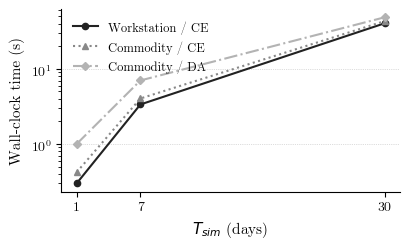

,hardware,coord_label,runs,expected_runs,complete,profile
0,Workstation HW,CE,135,135,True,Workstation HW / CE
1,Workstation HW,DA,0,135,False,Workstation HW / DA
2,Commodity HW,CE,135,135,True,Commodity HW / CE
3,Commodity HW,DA,135,135,True,Commodity HW / DA


,sim_days,profile,runs,wall_time_s,events_per_wall_s,max_rss_mb,total_output_size_mb
2,1,Workstation / CE,45,0.300,9106.3,35.60,0.089
0,1,Commodity / CE,45,0.422,6387.0,38.13,0.089
1,1,Commodity / DA,45,1.003,3661.9,39.61,0.152
5,7,Workstation / CE,45,3.361,5786.7,39.41,0.631
3,7,Commodity / CE,45,4.035,4789.4,42.12,0.632
4,7,Commodity / DA,45,7.009,3146.4,46.28,1.058
8,30,Workstation / CE,45,40.378,2140.0,54.29,2.746
6,30,Commodity / CE,45,43.165,1980.1,57.98,2.742
7,30,Commodity / DA,45,48.515,1703.7,74.86,4.557


In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ4/runs.csv')])
rq4 = ROOT / 'RQ4'
runs_path = rq4 / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

required_cols = {'coord_label', 'sim_days', 'item_spawning_time', 'n_robots', 'rep'}
missing_cols = sorted(required_cols - set(runs.columns))
if missing_cols:
    raise ValueError(f'RQ4 runs.csv is missing required columns: {missing_cols}')

numeric_cols = [
    'sim_days', 'item_spawning_time', 'n_robots', 'rep', 'wall_time_s', 'event_count',
    'events_per_wall_s', 'max_rss_mb', 'trace_size_mb', 'overhead_trace_size_mb',
    'total_output_size_mb',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

runs['coord_label'] = runs['coord_label'].astype(str).str.upper().str.strip()
runs = runs[runs['coord_label'].isin(['CE', 'DA'])].copy()
raw_machine = runs.get('machine_label', '')
runs['machine_label'] = raw_machine.fillna('').astype(str).str.lower().str.strip()


def hardware_profile(label):
    if label in {'', 'nan', 'none', 'null', 'workstation', 'ws'}:
        return 'Workstation HW'
    if label in {'mac', 'commodity', 'commodity-hardware', 'commodity_hw'}:
        return 'Commodity HW'
    return label.replace('_', ' ').replace('-', ' ').title()

runs['hardware'] = runs['machine_label'].map(hardware_profile)
runs['profile'] = runs['hardware'] + ' / ' + runs['coord_label']
hardware_order = ['Workstation HW', 'Commodity HW']
coord_order = ['CE', 'DA']
profile_order = [f'{hardware} / {coord}' for hardware, coord in product(hardware_order, coord_order)]
profile_labels = {
    'Workstation HW / CE': 'Workstation / CE',
    'Workstation HW / DA': 'Workstation / DA',
    'Commodity HW / CE': 'Commodity / CE',
    'Commodity HW / DA': 'Commodity / DA',
}

expected_per_profile = (
    runs['sim_days'].nunique()
    * runs['item_spawning_time'].nunique()
    * runs['n_robots'].nunique()
    * runs['rep'].nunique()
)
coverage_index = pd.MultiIndex.from_product([hardware_order, coord_order], names=['hardware', 'coord_label'])
coverage = (
    runs.groupby(['hardware', 'coord_label'])['run_id']
    .count()
    .reindex(coverage_index, fill_value=0)
    .reset_index(name='runs')
)
coverage['expected_runs'] = expected_per_profile
coverage['complete'] = coverage['runs'] >= coverage['expected_runs']
coverage['profile'] = coverage['hardware'] + ' / ' + coverage['coord_label']
missing_profiles = coverage.loc[~coverage['complete'], 'profile'].tolist()

summary = (
    runs.groupby(['sim_days', 'hardware', 'coord_label', 'profile'], as_index=False)
    .agg(
        runs=('run_id', 'count'),
        wall_time_s=('wall_time_s', 'mean'),
        events_per_wall_s=('events_per_wall_s', 'mean'),
        max_rss_mb=('max_rss_mb', 'mean'),
        total_output_size_mb=('total_output_size_mb', 'mean'),
    )
)
summary['hardware'] = pd.Categorical(summary['hardware'], categories=hardware_order, ordered=True)
summary['coord_label'] = pd.Categorical(summary['coord_label'], categories=coord_order, ordered=True)
summary['profile'] = pd.Categorical(summary['profile'], categories=profile_order, ordered=True)
summary = summary.sort_values(['sim_days', 'hardware', 'coord_label'])

resource_table = summary.copy()
resource_table['profile_label'] = resource_table['profile'].astype(str).map(profile_labels)
resource_table = resource_table[[
    'sim_days', 'profile_label', 'runs', 'wall_time_s', 'events_per_wall_s',
    'max_rss_mb', 'total_output_size_mb',
]].rename(columns={'profile_label': 'profile'})
resource_table = resource_table.round({
    'wall_time_s': 3,
    'events_per_wall_s': 1,
    'max_rss_mb': 2,
    'total_output_size_mb': 3,
})

sim_days_order = sorted(runs['sim_days'].dropna().unique())
series = {profile: summary[summary['profile'] == profile].set_index('sim_days') for profile in profile_order}
fig, ax = plt.subplots(1, 1, figsize=(4.2, 2.6))
for idx, profile in enumerate(profile_order):
    frame = series.get(profile)
    if frame is None or frame.empty:
        continue
    values = frame['wall_time_s'].reindex(sim_days_order)
    ax.plot(
        sim_days_order,
        values,
        label=profile_labels.get(profile, profile),
        color=LINE_COLORS[idx % len(LINE_COLORS)],
        linestyle=LINE_STYLES[idx % len(LINE_STYLES)],
        marker=MARKERS[idx % len(MARKERS)],
        linewidth=1.5,
        markersize=4.5,
    )
ax.set_xlabel('$T_{sim}$ (days)', fontsize=11)
ax.set_ylabel('Wall-clock time (s)', fontsize=11)
ax.set_yscale('log')
ax.set_xticks(sim_days_order)
ax.tick_params(axis='both', labelsize=10)
style_axes(ax, grid_axis='y')
ax.legend(loc='upper left', frameon=False, fontsize=9)
fig.tight_layout()
save_or_show(fig, ROOT, 'rq4_wall_time_scalability.pdf')
display(coverage)
display(resource_table)